# 🏦 Loan Approval Prediction
**Dataset:** Loan Approval Prediction Dataset (Kaggle)  
**Goal:** Predict whether a loan application will be Approved or Rejected.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/architsharma01/loan-approval-prediction-dataset/loan_approval_dataset.csv


## 1. Load Data

In [2]:
df = pd.read_csv('/kaggle/input/datasets/architsharma01/loan-approval-prediction-dataset/loan_approval_dataset.csv')
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [3]:
df.shape

(4269, 13)

In [4]:
df.columns

Index(['loan_id', ' no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='object')

In [5]:
df.dtypes

loan_id                       int64
 no_of_dependents             int64
 education                   object
 self_employed               object
 income_annum                 int64
 loan_amount                  int64
 loan_term                    int64
 cibil_score                  int64
 residential_assets_value     int64
 commercial_assets_value      int64
 luxury_assets_value          int64
 bank_asset_value             int64
 loan_status                 object
dtype: object

In [6]:
df.isnull().sum()

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


## 2. Exploratory Data Analysis

In [9]:
df[' loan_status'].value_counts()

 loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

In [10]:
df[' education'].value_counts()

 education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64

In [11]:
df[' self_employed'].value_counts()

 self_employed
Yes    2150
No     2119
Name: count, dtype: int64

In [12]:
df.groupby(' loan_status')[' cibil_score'].mean()

 loan_status
Approved    703.461973
Rejected    429.468072
Name:  cibil_score, dtype: float64

In [13]:
df.groupby(' loan_status')[' income_annum'].mean()

 loan_status
Approved    5.025904e+06
Rejected    5.113825e+06
Name:  income_annum, dtype: float64

In [14]:
df.groupby(' loan_status')[' loan_amount'].mean()

 loan_status
Approved    1.524725e+07
Rejected    1.494606e+07
Name:  loan_amount, dtype: float64

In [15]:
df.groupby(' loan_status')[' loan_term'].mean()

 loan_status
Approved    10.397590
Rejected    11.728456
Name:  loan_term, dtype: float64

In [16]:
df.groupby(' loan_status')[' residential_assets_value'].mean()

 loan_status
Approved    7.399812e+06
Rejected    7.592498e+06
Name:  residential_assets_value, dtype: float64

In [17]:
df[df[' residential_assets_value'] < 0]

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
59,60,4,Not Graduate,Yes,5500000,18200000,16,797,-100000,4900000,18600000,4800000,Approved
196,197,4,Not Graduate,Yes,400000,1500000,2,669,-100000,600000,900000,500000,Approved
559,560,2,Graduate,Yes,200000,500000,6,885,-100000,0,300000,200000,Rejected
702,703,4,Graduate,Yes,6300000,23900000,6,899,-100000,11400000,20600000,6700000,Approved
737,738,2,Graduate,Yes,900000,2500000,16,458,-100000,100000,3200000,1100000,Rejected
784,785,0,Graduate,No,5000000,14400000,2,761,-100000,7300000,12600000,4500000,Approved
904,905,2,Graduate,No,4100000,14900000,12,571,-100000,5200000,13000000,3400000,Approved
1089,1090,3,Graduate,No,5100000,11000000,6,336,-100000,5800000,11600000,7500000,Rejected
1163,1164,2,Graduate,No,4500000,9100000,18,593,-100000,600000,12400000,2500000,Approved
1350,1351,5,Graduate,No,4000000,13700000,6,496,-100000,1400000,15800000,3700000,Rejected


In [18]:
(df[' residential_assets_value'] == -100000).sum()

np.int64(28)

In [19]:
df[df[' residential_assets_value'] == -100000][
    [' residential_assets_value', ' commercial_assets_value',
     ' luxury_assets_value', ' bank_asset_value']
].describe()

,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,28.0,2.800000e+01,2.800000e+01,2.800000e+01
mean,-100000.0,3.160714e+06,8.325000e+06,2.735714e+06
std,0.0,3.612257e+06,7.967835e+06,2.533511e+06
min,-100000.0,0.000000e+00,3.000000e+05,1.000000e+05
25%,-100000.0,3.500000e+05,9.750000e+05,4.750000e+05
50%,-100000.0,1.250000e+06,6.150000e+06,2.300000e+06
75%,-100000.0,5.350000e+06,1.330000e+07,4.125000e+06
max,-100000.0,1.200000e+07,2.700000e+07,8.200000e+06


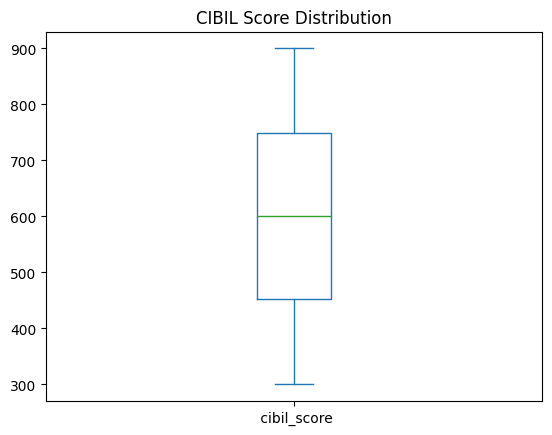

In [20]:
df[' cibil_score'].plot(kind='box')
plt.title('CIBIL Score Distribution')
plt.show()

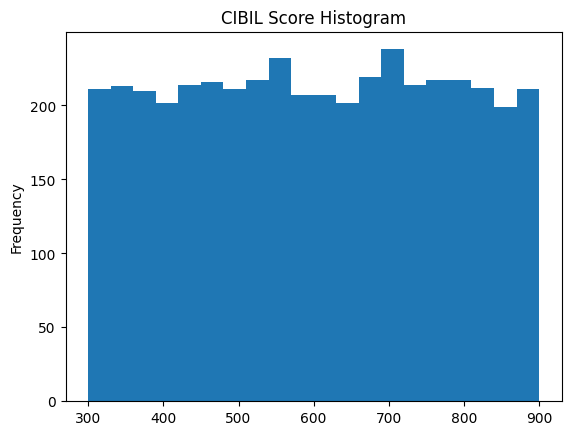

In [21]:
df[' cibil_score'].plot(kind='hist', bins=20)
plt.title('CIBIL Score Histogram')
plt.show()

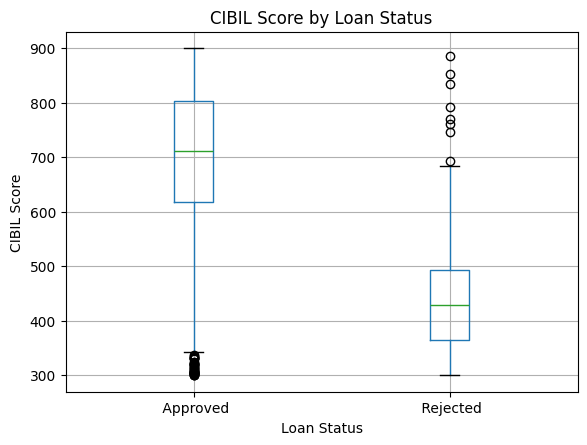

In [22]:
df.boxplot(column=' cibil_score', by=' loan_status')
plt.title('CIBIL Score by Loan Status')
plt.suptitle('')
plt.xlabel('Loan Status')
plt.ylabel('CIBIL Score')
plt.show()

In [23]:
df.groupby(' loan_status')[' cibil_score'].agg(['min','max','mean','median'])

,min,max,mean,median
loan_status,,,,
Approved,300,900,703.461973,711.0
Rejected,300,885,429.468072,429.0


In [24]:
high_cibil_rejected = df[
    (df[' cibil_score'] >= 700) &
    (df[' loan_status'] == ' Rejected')
]
high_cibil_rejected.head(10)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
236,237,3,Graduate,Yes,900000,3500000,4,770,700000,0,2000000,600000,Rejected
559,560,2,Graduate,Yes,200000,500000,6,885,-100000,0,300000,200000,Rejected
911,912,0,Graduate,Yes,1300000,4800000,4,835,500000,100000,3300000,800000,Rejected
1446,1447,1,Graduate,No,300000,1200000,18,747,100000,0,700000,200000,Rejected
3213,3214,1,Not Graduate,Yes,4300000,16300000,14,792,400000,400000,10200000,4000000,Rejected
3527,3528,0,Graduate,No,1800000,6900000,10,853,900000,400000,3700000,1700000,Rejected
4099,4100,3,Graduate,No,8700000,31100000,16,760,400000,1800000,19300000,4800000,Rejected


In [25]:
print(df[' loan_status'].unique())

[' Approved' ' Rejected']


In [26]:
print(df[' cibil_score'].max())

900


## 3. Data Cleaning & Feature Engineering

In [27]:
# Strip leading/trailing whitespace from column names and string columns
df.columns = df.columns.str.strip()
df['education']    = df['education'].str.strip()
df['self_employed'] = df['self_employed'].str.strip()
df['loan_status']   = df['loan_status'].str.strip()

In [28]:
# Confirm high-CIBIL rejections after cleaning
high_cibil_rejected = df[
    (df['cibil_score'] >= 700) &
    (df['loan_status'] == 'Rejected')
]
high_cibil_rejected.head(10)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
236,237,3,Graduate,Yes,900000,3500000,4,770,700000,0,2000000,600000,Rejected
559,560,2,Graduate,Yes,200000,500000,6,885,-100000,0,300000,200000,Rejected
911,912,0,Graduate,Yes,1300000,4800000,4,835,500000,100000,3300000,800000,Rejected
1446,1447,1,Graduate,No,300000,1200000,18,747,100000,0,700000,200000,Rejected
3213,3214,1,Not Graduate,Yes,4300000,16300000,14,792,400000,400000,10200000,4000000,Rejected
3527,3528,0,Graduate,No,1800000,6900000,10,853,900000,400000,3700000,1700000,Rejected
4099,4100,3,Graduate,No,8700000,31100000,16,760,400000,1800000,19300000,4800000,Rejected


In [29]:
# Feature engineering: loan-to-income ratio
df['loan_to_income_ratio'] = df['loan_amount'] / df['income_annum']
df[['income_annum', 'loan_amount', 'loan_to_income_ratio', 'loan_status']].head()

,income_annum,loan_amount,loan_to_income_ratio,loan_status
0,9600000,29900000,3.114583,Approved
1,4100000,12200000,2.975610,Rejected
2,9100000,29700000,3.263736,Rejected
3,8200000,30700000,3.743902,Rejected
4,9800000,24200000,2.469388,Rejected


In [30]:
df.groupby('loan_status')['loan_to_income_ratio'].mean()

loan_status
Approved    3.025512
Rejected    2.917779
Name: loan_to_income_ratio, dtype: float64

In [31]:
pd.crosstab(df['education'], df['loan_status'])

loan_status,Approved,Rejected
education,,
Graduate,1339,805
Not Graduate,1317,808


In [32]:
pd.crosstab(df['self_employed'], df['loan_status'])

loan_status,Approved,Rejected
self_employed,,
No,1318,801
Yes,1338,812


In [33]:
df.select_dtypes(include='number').corr()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_to_income_ratio
loan_id,1.000000,0.005326,0.012592,0.008170,0.009809,0.016323,0.020936,0.018595,-0.000862,0.010765,-0.011235
no_of_dependents,0.005326,1.000000,0.007266,-0.003366,-0.020111,-0.009998,0.007376,-0.001531,0.002817,0.011163,-0.029256
income_annum,0.012592,0.007266,1.000000,0.927470,0.011488,-0.023034,0.636841,0.640328,0.929145,0.851093,0.019714
loan_amount,0.008170,-0.003366,0.927470,1.000000,0.008437,-0.017035,0.594596,0.603188,0.860914,0.788122,0.340791
loan_term,0.009809,-0.020111,0.011488,0.008437,1.000000,0.007810,0.008016,-0.005478,0.012490,0.017177,-0.002876
cibil_score,0.016323,-0.009998,-0.023034,-0.017035,0.007810,1.000000,-0.019947,-0.003769,-0.028618,-0.015478,0.002980
residential_assets_value,0.020936,0.007376,0.636841,0.594596,0.008016,-0.019947,1.000000,0.414786,0.590932,0.527418,0.021176
commercial_assets_value,0.018595,-0.001531,0.640328,0.603188,-0.005478,-0.003769,0.414786,1.000000,0.591128,0.548576,0.029573
luxury_assets_value,-0.000862,0.002817,0.929145,0.860914,0.012490,-0.028618,0.590932,0.591128,1.000000,0.788517,0.018091
bank_asset_value,0.010765,0.011163,0.851093,0.788122,0.017177,-0.015478,0.527418,0.548576,0.788517,1.000000,0.017282


In [34]:
# Fix the one invalid residential_assets_value (-100000 → median)
median_val = df.loc[df['residential_assets_value'] != -100000, 'residential_assets_value'].median()
print("Median residential_assets_value:", median_val)

Median residential_assets_value: 5700000.0


In [35]:
df['residential_assets_value'] = df['residential_assets_value'].replace(-100000, 5700000)
df['residential_assets_value'].value_counts().sort_index().head(10)

residential_assets_value
0         45
100000    60
200000    50
300000    52
400000    66
500000    63
600000    56
700000    52
800000    45
900000    48
Name: count, dtype: int64

## 4. Train / Test Split

In [36]:
x = df.drop(columns=['loan_status', 'loan_id'])
y = df['loan_status']

print("x shape:", x.shape)
print("y shape:", y.shape)
print("\nFeatures:", x.columns.tolist())
print("Target values:", y.unique())

x shape: (4269, 12)
y shape: (4269,)

Features: ['no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_to_income_ratio']
Target values: ['Approved' 'Rejected']


In [37]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", x_train.shape[0])
print("Testing samples: ", x_test.shape[0])

Training samples: 3415
Testing samples:  854


## 5. Preprocessing Pipeline

In [38]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_features = ['education', 'self_employed']

numerical_features = [
    'no_of_dependents',
    'income_annum',
    'loan_amount',
    'loan_term',
    'cibil_score',
    'residential_assets_value',
    'commercial_assets_value',
    'luxury_assets_value',
    'bank_asset_value',
    'loan_to_income_ratio'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed  = preprocessor.transform(x_test)

print("Training shape:", x_train_processed.shape)
print("Testing shape: ", x_test_processed.shape)

Training shape: (3415, 12)
Testing shape:  (854, 12)


## 6. Model 1 — Logistic Regression

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

model = LogisticRegression(max_iter=1000)
model.fit(x_train_processed, y_train)

y_pred = model.predict(x_test_processed)
y_prob = model.predict_proba(x_test_processed)

print("Classes:", model.classes_)

Classes: ['Approved' 'Rejected']


In [40]:
# Test metrics
lr_accuracy  = accuracy_score(y_test, y_pred)
lr_precision = precision_score(y_test, y_pred, pos_label='Approved')
lr_recall    = recall_score(y_test, y_pred, pos_label='Approved')
lr_f1        = f1_score(y_test, y_pred, pos_label='Approved')

print("Logistic Regression Test Metrics")
print("----------------------------------")
print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1 Score :", lr_f1)

Logistic Regression Test Metrics
----------------------------------
Accuracy : 0.9168618266978923
Precision: 0.9212454212454212
Recall   : 0.9472693032015066
F1 Score : 0.9340761374187558


In [41]:
cm = confusion_matrix(y_test, y_pred, labels=['Approved', 'Rejected'])
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[503  28]
 [ 43 280]]


In [42]:
# Training metrics (check overfitting)
y_train_pred = model.predict(x_train_processed)

lr_train_accuracy  = accuracy_score(y_train, y_train_pred)
lr_train_precision = precision_score(y_train, y_train_pred, pos_label='Approved')
lr_train_recall    = recall_score(y_train, y_train_pred, pos_label='Approved')
lr_train_f1        = f1_score(y_train, y_train_pred, pos_label='Approved')

print("Logistic Regression Training Metrics")
print("--------------------------------------")
print("Accuracy :", lr_train_accuracy)
print("Precision:", lr_train_precision)
print("Recall   :", lr_train_recall)
print("F1 Score :", lr_train_f1)

Logistic Regression Training Metrics
--------------------------------------
Accuracy : 0.9086383601756954
Precision: 0.9234002802428771
Recall   : 0.9303529411764706
F1 Score : 0.9268635724331927


In [43]:
# Threshold analysis — Logistic Regression uses class index 0 = 'Approved'
approved_prob_lr = y_prob[:, list(model.classes_).index('Approved')]

for threshold in [0.50, 0.60, 0.70, 0.80]:
    y_pred_t = ['Approved' if p >= threshold else 'Rejected' for p in approved_prob_lr]
    p = precision_score(y_test, y_pred_t, pos_label='Approved')
    r = recall_score(y_test, y_pred_t, pos_label='Approved')
    f = f1_score(y_test, y_pred_t, pos_label='Approved')
    cm_t = confusion_matrix(y_test, y_pred_t, labels=['Approved', 'Rejected'])
    print(f"Threshold: {threshold}  Precision: {p:.4f}  Recall: {r:.4f}  F1: {f:.4f}")
    print(f"  TP={cm_t[0,0]}  FN={cm_t[0,1]}  FP={cm_t[1,0]}  TN={cm_t[1,1]}")
    print()

Threshold: 0.5  Precision: 0.9212  Recall: 0.9473  F1: 0.9341
  TP=503  FN=28  FP=43  TN=280

Threshold: 0.6  Precision: 0.9522  Recall: 0.9379  F1: 0.9450
  TP=498  FN=33  FP=25  TN=298

Threshold: 0.7  Precision: 0.9722  Recall: 0.9209  F1: 0.9458
  TP=489  FN=42  FP=14  TN=309

Threshold: 0.8  Precision: 0.9896  Recall: 0.8927  F1: 0.9386
  TP=474  FN=57  FP=5  TN=318



## 7. Model 2 — Decision Tree (Unpruned)

In [44]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(x_train_processed, y_train)
print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [45]:
y_pred_tree = decision_tree.predict(x_test_processed)

dt_accuracy  = accuracy_score(y_test, y_pred_tree)
dt_precision = precision_score(y_test, y_pred_tree, pos_label='Approved')
dt_recall    = recall_score(y_test, y_pred_tree, pos_label='Approved')
dt_f1        = f1_score(y_test, y_pred_tree, pos_label='Approved')

print("Decision Tree Test Metrics")
print("----------------------------")
print("Accuracy :", dt_accuracy)
print("Precision:", dt_precision)
print("Recall   :", dt_recall)
print("F1 Score :", dt_f1)

Decision Tree Test Metrics
----------------------------
Accuracy : 0.9941451990632318
Precision: 0.9962264150943396
Recall   : 0.9943502824858758
F1 Score : 0.9952874646559849


In [46]:
# Training metrics
y_train_pred_tree = decision_tree.predict(x_train_processed)

dt_train_accuracy  = accuracy_score(y_train, y_train_pred_tree)
dt_train_precision = precision_score(y_train, y_train_pred_tree, pos_label='Approved')
dt_train_recall    = recall_score(y_train, y_train_pred_tree, pos_label='Approved')
dt_train_f1        = f1_score(y_train, y_train_pred_tree, pos_label='Approved')

print("Decision Tree Training Metrics")
print("--------------------------------")
print("Accuracy :", dt_train_accuracy)
print("Precision:", dt_train_precision)
print("Recall   :", dt_train_recall)
print("F1 Score :", dt_train_f1)

Decision Tree Training Metrics
--------------------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


## 8. Model 3 — Decision Tree (Pruned, max_depth=5)

In [47]:
decision_tree_pruned = DecisionTreeClassifier(max_depth=5, random_state=42)
decision_tree_pruned.fit(x_train_processed, y_train)
print("Pruned Decision Tree trained successfully.")

Pruned Decision Tree trained successfully.


In [48]:
y_pred_tree_pruned = decision_tree_pruned.predict(x_test_processed)

dt_pruned_accuracy  = accuracy_score(y_test, y_pred_tree_pruned)
dt_pruned_precision = precision_score(y_test, y_pred_tree_pruned, pos_label='Approved')
dt_pruned_recall    = recall_score(y_test, y_pred_tree_pruned, pos_label='Approved')
dt_pruned_f1        = f1_score(y_test, y_pred_tree_pruned, pos_label='Approved')

print("Pruned Decision Tree Test Metrics")
print("-----------------------------------")
print("Accuracy :", dt_pruned_accuracy)
print("Precision:", dt_pruned_precision)
print("Recall   :", dt_pruned_recall)
print("F1 Score :", dt_pruned_f1)

Pruned Decision Tree Test Metrics
-----------------------------------
Accuracy : 0.9964871194379391
Precision: 0.9943820224719101
Recall   : 1.0
F1 Score : 0.9971830985915493


In [49]:
y_train_pred_pruned = decision_tree_pruned.predict(x_train_processed)

dt_pruned_train_accuracy  = accuracy_score(y_train, y_train_pred_pruned)
dt_pruned_train_precision = precision_score(y_train, y_train_pred_pruned, pos_label='Approved')
dt_pruned_train_recall    = recall_score(y_train, y_train_pred_pruned, pos_label='Approved')
dt_pruned_train_f1        = f1_score(y_train, y_train_pred_pruned, pos_label='Approved')

print("Pruned Decision Tree Training Metrics")
print("---------------------------------------")
print("Accuracy :", dt_pruned_train_accuracy)
print("Precision:", dt_pruned_train_precision)
print("Recall   :", dt_pruned_train_recall)
print("F1 Score :", dt_pruned_train_f1)

Pruned Decision Tree Training Metrics
---------------------------------------
Accuracy : 0.9973645680819913
Precision: 0.9957825679475164
Recall   : 1.0
F1 Score : 0.9978868278938718


In [50]:
# Feature importances
feature_importance = pd.Series(
    decision_tree_pruned.feature_importances_,
    index=preprocessor.get_feature_names_out()
).sort_values(ascending=False)

print(feature_importance)

num__cibil_score                 0.820403
num__loan_to_income_ratio        0.089793
num__loan_term                   0.083376
num__loan_amount                 0.002389
num__commercial_assets_value     0.001288
num__bank_asset_value            0.001253
num__residential_assets_value    0.000870
num__luxury_assets_value         0.000628
num__no_of_dependents            0.000000
num__income_annum                0.000000
cat__education_Not Graduate      0.000000
cat__self_employed_Yes           0.000000
dtype: float64


In [51]:
from sklearn.tree import export_text

tree_rules = export_text(
    decision_tree_pruned,
    feature_names=list(preprocessor.get_feature_names_out())
)
print(tree_rules)

|--- num__cibil_score <= -0.28
|   |--- num__loan_term <= -1.03
|   |   |--- num__loan_to_income_ratio <= 0.02
|   |   |   |--- class: Rejected
|   |   |--- num__loan_to_income_ratio >  0.02
|   |   |   |--- num__residential_assets_value <= -1.16
|   |   |   |   |--- num__luxury_assets_value <= -1.26
|   |   |   |   |   |--- class: Rejected
|   |   |   |   |--- num__luxury_assets_value >  -1.26
|   |   |   |   |   |--- class: Approved
|   |   |   |--- num__residential_assets_value >  -1.16
|   |   |   |   |--- num__cibil_score <= -1.72
|   |   |   |   |   |--- class: Approved
|   |   |   |   |--- num__cibil_score >  -1.72
|   |   |   |   |   |--- class: Approved
|   |--- num__loan_term >  -1.03
|   |   |--- class: Rejected
|--- num__cibil_score >  -0.28
|   |--- num__residential_assets_value <= -1.00
|   |   |--- num__loan_amount <= 1.77
|   |   |   |--- num__loan_to_income_ratio <= 1.20
|   |   |   |   |--- num__residential_assets_value <= -1.16
|   |   |   |   |   |--- class: Approve

## 9. Model 4 — Random Forest

In [52]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(n_estimators=100, random_state=42)
random_forest.fit(x_train_processed, y_train)
print("Random Forest trained successfully.")

Random Forest trained successfully.


In [53]:
y_pred_rf = random_forest.predict(x_test_processed)

rf_accuracy  = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, pos_label='Approved')
rf_recall    = recall_score(y_test, y_pred_rf, pos_label='Approved')
rf_f1        = f1_score(y_test, y_pred_rf, pos_label='Approved')

print("Random Forest Test Metrics")
print("----------------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)

Random Forest Test Metrics
----------------------------
Accuracy : 0.9964871194379391
Precision: 0.9943820224719101
Recall   : 1.0
F1 Score : 0.9971830985915493


In [54]:
y_pred_rf_train = random_forest.predict(x_train_processed)

rf_train_accuracy  = accuracy_score(y_train, y_pred_rf_train)
rf_train_precision = precision_score(y_train, y_pred_rf_train, pos_label='Approved')
rf_train_recall    = recall_score(y_train, y_pred_rf_train, pos_label='Approved')
rf_train_f1        = f1_score(y_train, y_pred_rf_train, pos_label='Approved')

print("Random Forest Training Metrics")
print("--------------------------------")
print("Accuracy :", rf_train_accuracy)
print("Precision:", rf_train_precision)
print("Recall   :", rf_train_recall)
print("F1 Score :", rf_train_f1)

Random Forest Training Metrics
--------------------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


## 10. Baseline — CIBIL Score Only

In [55]:
cibil_tree = DecisionTreeClassifier(max_depth=5, random_state=42)
cibil_tree.fit(x_train[['cibil_score']], y_train)
cibil_pred = cibil_tree.predict(x_test[['cibil_score']])
print("CIBIL-only Accuracy:", accuracy_score(y_test, cibil_pred))

CIBIL-only Accuracy: 0.9601873536299765


## 11. Model Comparison

In [56]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree (Unpruned)',
        'Decision Tree (Pruned)',
        'Random Forest'
    ],
    'Test Accuracy':  [lr_accuracy,  dt_accuracy,  dt_pruned_accuracy,  rf_accuracy],
    'Test Precision': [lr_precision, dt_precision, dt_pruned_precision, rf_precision],
    'Test Recall':    [lr_recall,    dt_recall,    dt_pruned_recall,    rf_recall],
    'Test F1':        [lr_f1,        dt_f1,        dt_pruned_f1,        rf_f1],
})

print(model_comparison.to_string(index=False))

                   Model  Test Accuracy  Test Precision  Test Recall  Test F1
     Logistic Regression       0.916862        0.921245     0.947269 0.934076
Decision Tree (Unpruned)       0.994145        0.996226     0.994350 0.995287
  Decision Tree (Pruned)       0.996487        0.994382     1.000000 0.997183
           Random Forest       0.996487        0.994382     1.000000 0.997183


## 12. Hyperparameter Tuning — GridSearchCV

In [57]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

approved_f1_scorer = make_scorer(f1_score, pos_label='Approved')

param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 7, 8],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring=approved_f1_scorer,
    n_jobs=-1
)

grid_search.fit(x_train_processed, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)

Best Parameters: {'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2}
Best CV F1 Score: 0.9964818784184176


In [58]:
best_tree = grid_search.best_estimator_
print("Best Decision Tree:")
print(best_tree)

Best Decision Tree:
DecisionTreeClassifier(max_depth=3, min_samples_leaf=2, random_state=42)


In [59]:
y_pred_best_tree = best_tree.predict(x_test_processed)

best_tree_accuracy  = accuracy_score(y_test, y_pred_best_tree)
best_tree_precision = precision_score(y_test, y_pred_best_tree, pos_label='Approved')
best_tree_recall    = recall_score(y_test, y_pred_best_tree, pos_label='Approved')
best_tree_f1        = f1_score(y_test, y_pred_best_tree, pos_label='Approved')

print("Tuned Decision Tree Test Metrics")
print("----------------------------------")
print("Accuracy :", best_tree_accuracy)
print("Precision:", best_tree_precision)
print("Recall   :", best_tree_recall)
print("F1 Score :", best_tree_f1)

Tuned Decision Tree Test Metrics
----------------------------------
Accuracy : 0.9964871194379391
Precision: 0.9943820224719101
Recall   : 1.0
F1 Score : 0.9971830985915493


In [60]:
y_train_pred_best_tree = best_tree.predict(x_train_processed)

best_tree_train_accuracy  = accuracy_score(y_train, y_train_pred_best_tree)
best_tree_train_precision = precision_score(y_train, y_train_pred_best_tree, pos_label='Approved')
best_tree_train_recall    = recall_score(y_train, y_train_pred_best_tree, pos_label='Approved')
best_tree_train_f1        = f1_score(y_train, y_train_pred_best_tree, pos_label='Approved')

print("Tuned Decision Tree Training Metrics")
print("--------------------------------------")
print("Accuracy :", best_tree_train_accuracy)
print("Precision:", best_tree_train_precision)
print("Recall   :", best_tree_train_recall)
print("F1 Score :", best_tree_train_f1)

Tuned Decision Tree Training Metrics
--------------------------------------
Accuracy : 0.9961932650073206
Precision: 0.9939195509822264
Recall   : 1.0
F1 Score : 0.9969505043396669


In [61]:
final_tree_cm = confusion_matrix(y_test, y_pred_best_tree, labels=['Approved', 'Rejected'])
print("Confusion Matrix — Tuned Decision Tree:")
print(final_tree_cm)

Confusion Matrix — Tuned Decision Tree:
[[531   0]
 [  3 320]]


## 13. Decision Tree Visualization

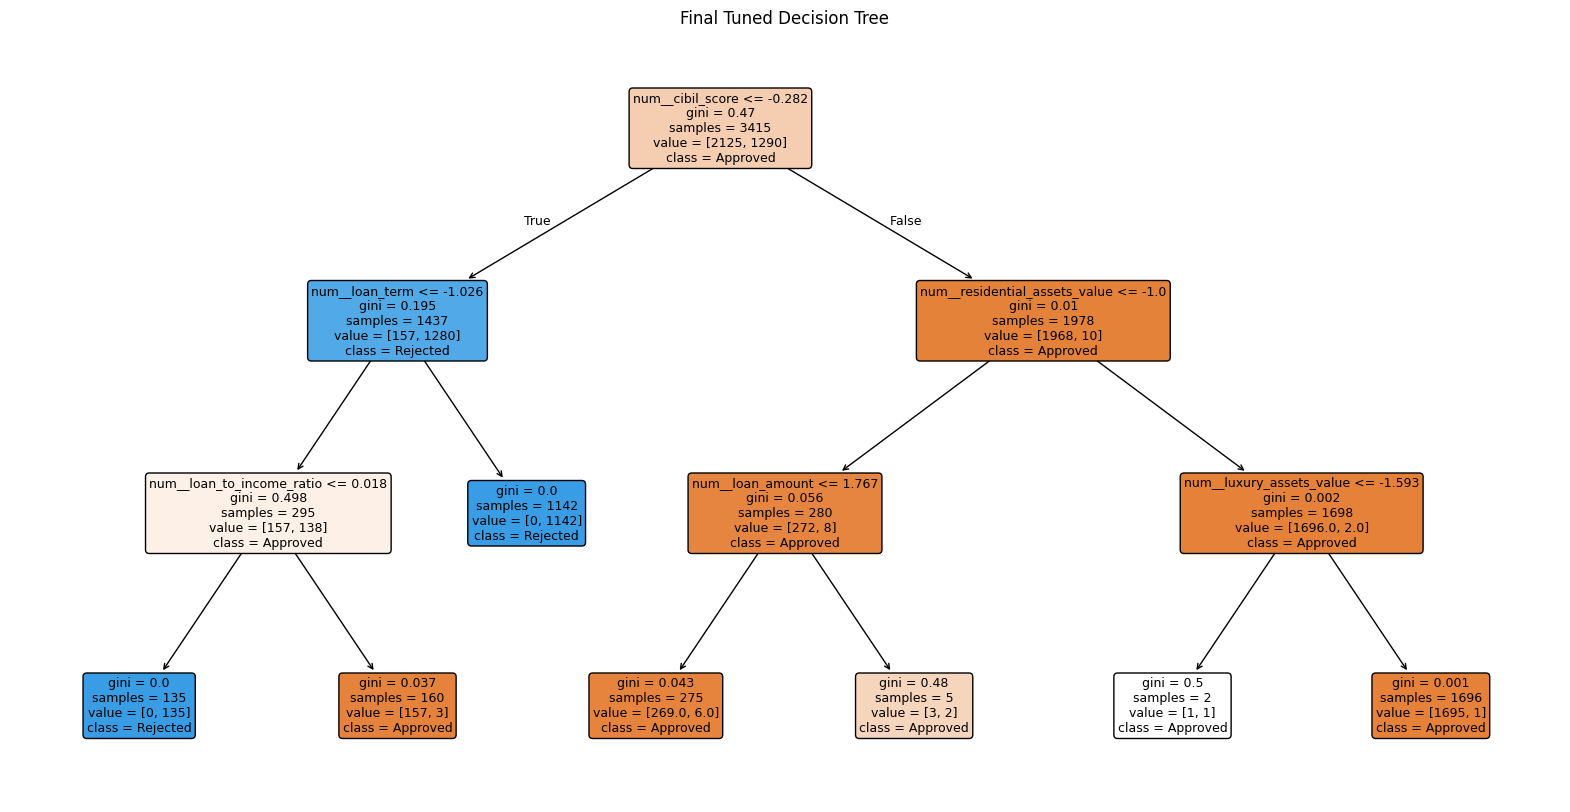

In [62]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    best_tree,
    feature_names=list(preprocessor.get_feature_names_out()),  # FIXED: use preprocessed names
    class_names=best_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Final Tuned Decision Tree")
plt.show()

In [63]:
# Decode tree thresholds back to original units
scaler = preprocessor.named_transformers_['num']
tree_internal = best_tree.tree_
processed_names = list(preprocessor.get_feature_names_out())

print("Decision Tree Split Thresholds (original units):\n")

for node in range(tree_internal.node_count):
    fi = tree_internal.feature[node]
    if fi >= 0:
        fname = processed_names[fi]
        threshold = tree_internal.threshold[node]
        if fi < len(numerical_features):
            original_val = threshold * scaler.scale_[fi] + scaler.mean_[fi]
            print(f"Node {node}: {fname} <= {original_val:.2f}")
        else:
            print(f"Node {node}: {fname} <= {threshold:.4f} (binary encoded)")

Decision Tree Split Thresholds (original units):

Node 0: num__cibil_score <= 549.50
Node 1: num__loan_term <= 5.00
Node 2: num__loan_to_income_ratio <= 2.99
Node 6: num__residential_assets_value <= 1050000.04
Node 7: num__loan_amount <= 30950000.09
Node 10: num__luxury_assets_value <= 599999.88


## 14. Additional Analysis

In [64]:
# Key statistics by loan status
print("Loan Amount by Status:")
print(df.groupby('loan_status')['loan_amount'].agg(['min','max','mean','median']))
print()
print("Income by Status:")
print(df.groupby('loan_status')['income_annum'].agg(['min','max','mean','median']))
print()
print("CIBIL Score by Status:")
print(df.groupby('loan_status')['cibil_score'].agg(['min','max','mean','median','std']))

Loan Amount by Status:
                min       max          mean      median
loan_status                                            
Approved     300000  39500000  1.524725e+07  14600000.0
Rejected     300000  38200000  1.494606e+07  14500000.0

Income by Status:
                min      max          mean     median
loan_status                                          
Approved     200000  9900000  5.025904e+06  5000000.0
Rejected     200000  9900000  5.113825e+06  5100000.0

CIBIL Score by Status:
             min  max        mean  median         std
loan_status                                          
Approved     300  900  703.461973   711.0  125.249016
Rejected     300  885  429.468072   429.0   78.401752


In [65]:
# Correlation of numerical features with loan outcome
df_analysis = df.copy()
df_analysis['loan_status_encoded'] = df_analysis['loan_status'].map({'Rejected': 0, 'Approved': 1})

numeric_cols = numerical_features  # already defined above

correlation = (
    df_analysis[numeric_cols + ['loan_status_encoded']]
    .corr()['loan_status_encoded']
    .drop('loan_status_encoded')
    .sort_values(key=abs, ascending=False)
)
print("Feature correlation with loan status:")
print(correlation)

Feature correlation with loan status:
cibil_score                 0.770518
loan_term                  -0.113036
loan_to_income_ratio        0.087726
no_of_dependents           -0.018114
loan_amount                 0.016150
luxury_assets_value        -0.015465
income_annum               -0.015189
residential_assets_value   -0.015042
commercial_assets_value     0.008246
bank_asset_value           -0.006778
Name: loan_status_encoded, dtype: float64


In [66]:
# Data quality checks
print("Duplicate rows:", df.duplicated().sum())
print("Total rows:", len(df))

feature_columns = [
    'no_of_dependents', 'education', 'self_employed',
    'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
    'residential_assets_value', 'commercial_assets_value',
    'luxury_assets_value', 'bank_asset_value', 'loan_to_income_ratio'
]

status_conflicts = df.groupby(feature_columns)['loan_status'].nunique()
conflicting = status_conflicts[status_conflicts > 1]
print("Conflicting applicant groups (same features, different outcome):", len(conflicting))

Duplicate rows: 0
Total rows: 4269
Conflicting applicant groups (same features, different outcome): 0


In [67]:
# Feature overlap between train and test
train_tuples = set(x_train.astype(str).apply(tuple, axis=1))
test_tuples  = set(x_test.astype(str).apply(tuple, axis=1))
overlap = train_tuples.intersection(test_tuples)

print("Unique training rows:", len(train_tuples))
print("Unique testing rows: ", len(test_tuples))
print("Exact overlap:", len(overlap))

Unique training rows: 3415
Unique testing rows:  854
Exact overlap: 0


## 15. Save Model & Preprocessor

In [68]:
import joblib

joblib.dump(best_tree, 'best_tree_model.pkl')
joblib.dump(preprocessor, 'preprocessor.pkl')

print("Model saved: best_tree_model.pkl")
print("Preprocessor saved: preprocessor.pkl")

Model saved: best_tree_model.pkl
Preprocessor saved: preprocessor.pkl


## 16. Prediction Function

In [69]:
def predict_loan(
    no_of_dependents,
    education,
    self_employed,
    income_annum,
    loan_amount,
    loan_term,
    cibil_score,
    residential_assets_value,
    commercial_assets_value,
    luxury_assets_value,
    bank_asset_value
):
    loan_to_income_ratio = loan_amount / income_annum

    input_data = pd.DataFrame({
        'no_of_dependents':         [no_of_dependents],
        'education':                [education],
        'self_employed':            [self_employed],
        'income_annum':             [income_annum],
        'loan_amount':              [loan_amount],
        'loan_term':                [loan_term],
        'cibil_score':              [cibil_score],
        'residential_assets_value': [residential_assets_value],
        'commercial_assets_value':  [commercial_assets_value],
        'luxury_assets_value':      [luxury_assets_value],
        'bank_asset_value':         [bank_asset_value],
        'loan_to_income_ratio':     [loan_to_income_ratio]
    })

    input_processed = preprocessor.transform(input_data)
    prediction      = best_tree.predict(input_processed)[0]
    probabilities   = best_tree.predict_proba(input_processed)[0]
    class_probs     = dict(zip(best_tree.classes_, probabilities))

    return prediction, class_probs

In [70]:
# Test Case 1 — Strong applicant (Expected: Approved)
prediction, probabilities = predict_loan(
    no_of_dependents=2,
    education='Graduate',
    self_employed='No',
    income_annum=5000000,
    loan_amount=15000000,
    loan_term=10,
    cibil_score=750,
    residential_assets_value=7000000,
    commercial_assets_value=4000000,
    luxury_assets_value=15000000,
    bank_asset_value=5000000
)

print("===================================")
print("       LOAN APPROVAL RESULT")
print("===================================")
print(f"Loan Status:          {prediction}")
print(f"Approved Probability: {probabilities['Approved']*100:.2f}%")
print(f"Rejected Probability: {probabilities['Rejected']*100:.2f}%")

       LOAN APPROVAL RESULT
Loan Status:          Approved
Approved Probability: 99.94%
Rejected Probability: 0.06%


In [71]:
# Test Case 2 — Weak applicant (Expected: Rejected)
prediction, probabilities = predict_loan(
    no_of_dependents=3,
    education='Not Graduate',
    self_employed='Yes',
    income_annum=2000000,
    loan_amount=8000000,
    loan_term=18,
    cibil_score=400,
    residential_assets_value=1000000,
    commercial_assets_value=500000,
    luxury_assets_value=2000000,
    bank_asset_value=1000000
)

print("===================================")
print("       LOAN APPROVAL RESULT")
print("===================================")
print(f"Loan Status:          {prediction}")
print(f"Approved Probability: {probabilities['Approved']*100:.2f}%")
print(f"Rejected Probability: {probabilities['Rejected']*100:.2f}%")

       LOAN APPROVAL RESULT
Loan Status:          Rejected
Approved Probability: 0.00%
Rejected Probability: 100.00%


In [72]:
# Test Case 3 — Borderline applicant (cibil_score=600)
prediction, probabilities = predict_loan(
    no_of_dependents=2,
    education='Graduate',
    self_employed='No',
    income_annum=5000000,
    loan_amount=15000000,
    loan_term=12,
    cibil_score=600,
    residential_assets_value=5000000,
    commercial_assets_value=3000000,
    luxury_assets_value=10000000,
    bank_asset_value=4000000
)

print("===================================")
print("       LOAN APPROVAL RESULT")
print("===================================")
print(f"Loan Status:          {prediction}")
print(f"Approved Probability: {probabilities['Approved']*100:.2f}%")
print(f"Rejected Probability: {probabilities['Rejected']*100:.2f}%")

       LOAN APPROVAL RESULT
Loan Status:          Approved
Approved Probability: 99.94%
Rejected Probability: 0.06%


In [73]:
import gradio as gr

def loan_prediction_interface(
    no_of_dependents,
    education,
    self_employed,
    income_annum,
    loan_amount,
    loan_term,
    cibil_score,
    residential_assets_value,
    commercial_assets_value,
    luxury_assets_value,
    bank_asset_value
):
    # Input validation
    if not (0 <= no_of_dependents <= 5):
        return "⚠️ Invalid Input\n\nNumber of dependents must be between 0 and 5."
    if education not in ["Graduate", "Not Graduate"]:
        return "⚠️ Invalid Input\n\nPlease select a valid education category."
    if self_employed not in ["Yes", "No"]:
        return "⚠️ Invalid Input\n\nPlease select a valid self-employed option."
    if not (200000 <= income_annum <= 9900000):
        return "⚠️ Invalid Input\n\nAnnual income must be between ₹200,000 and ₹9,900,000."
    if not (300000 <= loan_amount <= 39500000):
        return "⚠️ Invalid Input\n\nLoan amount must be between ₹300,000 and ₹39,500,000."
    if not (2 <= loan_term <= 20):
        return "⚠️ Invalid Input\n\nLoan term must be between 2 and 20 years."
    if not (300 <= cibil_score <= 900):
        return "⚠️ Invalid Input\n\nCIBIL score must be between 300 and 900."
    if not (0 <= residential_assets_value <= 29100000):
        return "⚠️ Invalid Input\n\nResidential asset value is outside the supported range."
    if not (0 <= commercial_assets_value <= 19400000):
        return "⚠️ Invalid Input\n\nCommercial asset value is outside the supported range."
    if not (300000 <= luxury_assets_value <= 39200000):
        return "⚠️ Invalid Input\n\nLuxury asset value must be between ₹300,000 and ₹39,200,000."
    if not (0 <= bank_asset_value <= 14700000):
        return "⚠️ Invalid Input\n\nBank asset value is outside the supported range."

    loan_to_income_ratio = loan_amount / income_annum

    prediction, probabilities = predict_loan(
        no_of_dependents, education, self_employed,
        income_annum, loan_amount, loan_term, cibil_score,
        residential_assets_value, commercial_assets_value,
        luxury_assets_value, bank_asset_value
    )

    approved_prob = probabilities['Approved'] * 100
    rejected_prob = probabilities['Rejected'] * 100

    return (
        "====================================\n"
        "       LOAN APPROVAL RESULT\n"
        "====================================\n\n"
        f"Loan Status:          {prediction}\n\n"
        f"Approved Probability: {approved_prob:.2f}%\n"
        f"Rejected Probability: {rejected_prob:.2f}%\n\n"
        f"Loan-to-Income Ratio: {loan_to_income_ratio:.2f}"
    )


with gr.Blocks(title="Personal Loan Approval System") as demo:

    gr.Markdown("""
    # 🏦 Personal Loan Approval Prediction System
    ### Enter the applicant's information below
    """)

    with gr.Row():
        with gr.Column():
            no_of_dependents        = gr.Number(label="Number of Dependents (0–5)", value=2, precision=0)
            education               = gr.Dropdown(choices=["Graduate", "Not Graduate"], label="Education", value="Graduate")
            self_employed           = gr.Dropdown(choices=["Yes", "No"], label="Self Employed", value="No")
            income_annum            = gr.Number(label="Annual Income (₹)", value=5000000, precision=0)
            loan_amount             = gr.Number(label="Loan Amount (₹)", value=15000000, precision=0)
            loan_term               = gr.Number(label="Loan Term (Years)", value=10, precision=0)

        with gr.Column():
            cibil_score                  = gr.Number(label="CIBIL Score (300–900)", value=750, precision=0)
            residential_assets_value     = gr.Number(label="Residential Assets Value (₹)", value=7000000, precision=0)
            commercial_assets_value      = gr.Number(label="Commercial Assets Value (₹)", value=4000000, precision=0)
            luxury_assets_value          = gr.Number(label="Luxury Assets Value (₹)", value=15000000, precision=0)
            bank_asset_value             = gr.Number(label="Bank Asset Value (₹)", value=5000000, precision=0)

    predict_button = gr.Button("🔍 Predict Loan Approval")
    result = gr.Textbox(label="Prediction Result", lines=8)

    predict_button.click(
        fn=loan_prediction_interface,
        inputs=[
            no_of_dependents, education, self_employed,
            income_annum, loan_amount, loan_term, cibil_score,
            residential_assets_value, commercial_assets_value,
            luxury_assets_value, bank_asset_value
        ],
        outputs=result
    )

demo.launch()

* Running on local URL:  http://127.0.0.1:7860
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

* Running on public URL: https://b2ee42962dd9bdbb79.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
